##### Copyright 2026 The Contributors

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
See the LICENSE file in the repository root.


# 05 — Evaluation

Three metric families, from most abstract to most operational:

1. **Classification** (Stage 1 gate): AUC, precision, recall
2. **Regression** (Stage 2 count): RMSE, MAE, Spearman correlation
3. **Operational** (what a field team actually experiences): Precision@K,
   Efficiency@K (fraction of all cases captured), Lift@K vs random visits

We also build two trivial **baselines inline** (last month's count, and
random ranking) so the two-stage model's value is measured against
something a health department could already do without any ML, not against
an abstract "AUC = 0.8 sounds good" number.

## Prerequisites
- Trained models in `artifacts/models/` (notebook `04`)
- `artifacts/test.csv` (notebook `03`)


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
print("ROOT =", ROOT)


ROOT = /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks


In [2]:
from utils import ARTIFACTS_DIR, load_data
from pipeline.training import load_models, predict_two_stage
from pipeline.evaluation import evaluate_classification, evaluate_regression, evaluate_operational

bundle = load_models()
test_df = load_data(ARTIFACTS_DIR / "test.csv")
feature_cols = bundle["feature_cols"]
X_te = test_df[feature_cols].fillna(0)
pred, gate = predict_two_stage(bundle["stage1"], bundle["stage2"], X_te, bundle["calibrator"])
print(f"Test set: {len(test_df)} hexagon-months, {int(test_df['has_any_cases'].sum())} with a future case")


Test set: 600 hexagon-months, 351 with a future case


In [3]:
GATE_REPORT_THRESHOLD = 0.30  # matches production TIER_THRESHOLDS["HIGH_PROB"]
cls = evaluate_classification(test_df["has_any_cases"], gate, threshold=GATE_REPORT_THRESHOLD)
reg = evaluate_regression(test_df["target_cases"], pred)
ops = evaluate_operational(test_df["target_cases"], pred, gate, k_values=[10, 20, 50])
{"classification": cls, "regression": reg, "operational": ops}


INFO | Gate AUC=0.704 P=0.610 R=0.963


INFO | Count RMSE=1.040 MAE=0.805 Spearman=0.411


INFO | K=10 Precision@K=0.80 Efficiency@K=0.04 Lift=2.2x


INFO | K=20 Precision@K=0.80 Efficiency@K=0.06 Lift=1.9x


INFO | K=50 Precision@K=0.80 Efficiency@K=0.14 Lift=1.6x


{'classification': {'auc_roc': 0.7044931864208972,
  'accuracy': 0.6183333333333333,
  'precision': 0.6101083032490975,
  'recall': 0.9629629629629629,
  'f1': 0.7469613259668508,
  'threshold': 0.3},
 'regression': {'rmse': 1.0404359195571897,
  'mae': 0.8050504124164581,
  'r2': 0.15534546740995203,
  'spearman': 0.4112515225950716},
 'operational': {'precision_at_10': 0.8,
  'efficiency_at_10': 0.03636363636363636,
  'cases_at_10': 22.0,
  'lift_at_10': 2.181818181818182,
  'precision_at_20': 0.8,
  'efficiency_at_20': 0.0628099173553719,
  'cases_at_20': 38.0,
  'lift_at_20': 1.8842975206611572,
  'precision_at_50': 0.8,
  'efficiency_at_50': 0.1371900826446281,
  'cases_at_50': 83.0,
  'lift_at_50': 1.6462809917355372}}

## ROC curve and predicted-vs-actual


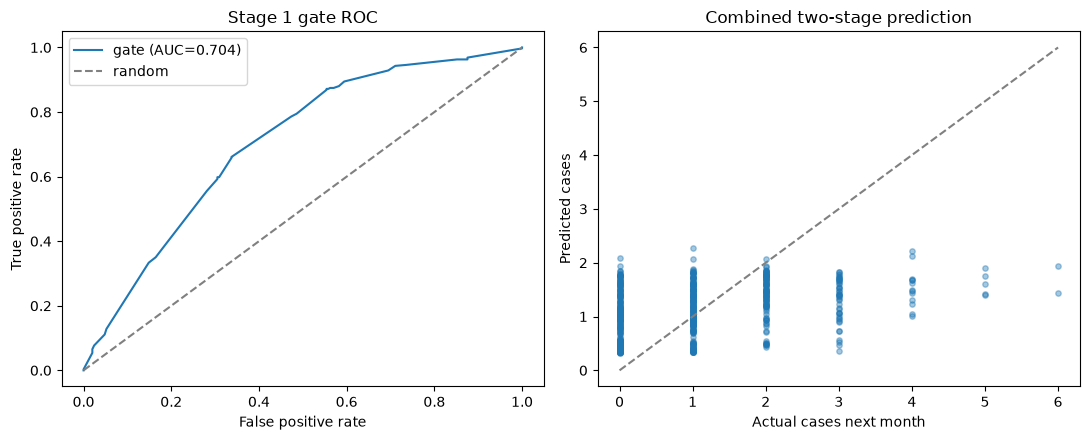

In [4]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

fpr, tpr, _ = roc_curve(test_df["has_any_cases"], gate)
axes[0].plot(fpr, tpr, label=f"gate (AUC={roc_auc_score(test_df['has_any_cases'], gate):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("Stage 1 gate ROC"); axes[0].legend()

axes[1].scatter(test_df["target_cases"], pred, alpha=0.4, s=15)
max_v = max(test_df["target_cases"].max(), pred.max(), 1)
axes[1].plot([0, max_v], [0, max_v], "--", color="grey")
axes[1].set_xlabel("Actual cases next month"); axes[1].set_ylabel("Predicted cases")
axes[1].set_title("Combined two-stage prediction")
plt.tight_layout()
plt.show()


## Baselines, computed by hand

Two trivial competitors:

- **Persistence baseline**: "next month will look like this month" (rank by
  `cases_t_minus_1` / current `total_cases`, if present as a feature)
- **Random baseline**: shuffle the ranking

If the two-stage model's Lift@20 isn't meaningfully better than the
persistence baseline's, that's a real finding worth reporting -- not
something to hide.


In [5]:
import numpy as np
from pipeline.evaluation import evaluate_operational

rng = np.random.default_rng(0)

persistence_col = "cases_t_minus_1" if "cases_t_minus_1" in test_df.columns else None
if persistence_col:
    persistence_pred = test_df[persistence_col].fillna(0).values
    persistence_gate = (persistence_pred > 0).astype(float)
    persistence_ops = evaluate_operational(test_df["target_cases"], persistence_pred, persistence_gate, k_values=[10, 20, 50])
else:
    persistence_ops = None

random_pred = rng.permutation(test_df["target_cases"].values)
random_gate = rng.random(len(test_df))
random_ops = evaluate_operational(test_df["target_cases"], random_pred, random_gate, k_values=[10, 20, 50])

comparison = pd.DataFrame({
    "two_stage_model": ops,
    "persistence_baseline": persistence_ops or {},
    "random_baseline": random_ops,
}).T
comparison[[c for c in comparison.columns if c.startswith("lift_at")]]


INFO | K=10 Precision@K=0.70 Efficiency@K=0.02 Lift=1.1x


INFO | K=20 Precision@K=0.80 Efficiency@K=0.04 Lift=1.3x


INFO | K=50 Precision@K=0.76 Efficiency@K=0.12 Lift=1.4x


INFO | K=10 Precision@K=0.30 Efficiency@K=0.01 Lift=0.6x


INFO | K=20 Precision@K=0.45 Efficiency@K=0.02 Lift=0.6x


INFO | K=50 Precision@K=0.62 Efficiency@K=0.10 Lift=1.2x


,lift_at_10,lift_at_20,lift_at_50
two_stage_model,2.181818,1.884298,1.646281
persistence_baseline,1.090909,1.338843,1.388430
random_baseline,0.595041,0.644628,1.249587


## Walk-forward validation (optional, slower)

Retrains on months `1..t` and scores month `t+1`, for every `t` -- the most
honest estimate of real-world performance since it never lets the model see
"future" months even during model *selection*, only during final scoring.


In [6]:
from pipeline.evaluation import walk_forward_auc

labeled = load_data(ARTIFACTS_DIR / "labeled.csv")
labeled["month"] = pd.to_datetime(labeled["month"])
wf = walk_forward_auc(labeled, feature_cols, min_train_months=3)
wf


INFO | Stage 1 gate val AUC: 0.5000 | AP: 0.6944


INFO | Gate calibrated AP: 0.6944 (raw AP: 0.6944)


INFO | Stage 2 non-zero val RMSE: 1.0698144834596002


INFO | Walk-forward 2024-04-01 AUC=0.500 RMSE=1.100


INFO | Stage 1 gate val AUC: 0.6654 | AP: 0.7871


...

INFO | Stage 1 gate val AUC: 0.7318 | AP: 0.7998


INFO | Gate calibrated AP: 0.8036 (raw AP: 0.7998)


INFO | Stage 2 non-zero val RMSE: 1.0238652383471198


INFO | Walk-forward 2025-07-01 AUC=0.694 RMSE=1.011


,test_month,n_train,n_test,auc,rmse
0,2024-04-01,900,300,0.500000,1.100160
1,2024-05-01,1200,300,0.706376,1.225259
2,2024-06-01,1500,300,0.677012,1.223611
3,2024-07-01,1800,300,0.674339,1.031088
4,2024-08-01,2100,300,0.678586,1.028512
5,2024-09-01,2400,300,0.628981,0.898829
6,2024-10-01,2700,300,0.612163,1.027444
7,2024-11-01,3000,300,0.707727,0.971838
8,2024-12-01,3300,300,0.717011,1.142724
9,2025-01-01,3600,300,0.697453,1.096858
